In [1]:
!pip install xgboost pandas scikit-learn

In [2]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load the converted CSV file
df = pd.read_csv('football_train_data.csv')

print("Data loaded successfully!")
print("Dataset Shape (Rows, Columns):", df.shape)

# 2. Define your target variable 
# (Make sure 'FTR' matches your actual target column name in Excel for full-time result)
target_col = 'FTR' 

# Drop non-numeric metadata and the target from your feature matrix
X = df.drop(columns=[target_col, 'HomeTeam', 'AwayTeam', 'Date'], errors='ignore')
y = df[target_col]

# Convert text-based targets (like 'H', 'D', 'A') into numeric codes for XGBoost
if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 3. Split data into training (80%) and validation (20%) sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize and train the XGBoost classifier
model = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model.fit(X_train, y_train)

# 5. Evaluate the model performance
preds = model.predict(X_val)
print("Baseline Validation Accuracy:", accuracy_score(y_val, preds))

Data loaded successfully!
Dataset Shape (Rows, Columns): (37824, 90)
Baseline Validation Accuracy: 0.561929940515532


In [3]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# 1. Load dataset
df = pd.read_csv('football_train_data.csv')
target_col = 'FTR'

# 2. Automatically identify and drop columns from competing bookmakers (GB, IW, LB, SO, SB, WH)
# while keeping match stats and Bet365 odds intact
other_bookie_prefixes = ('GB', 'IW', 'LB', 'SO', 'SB', 'WH')
cols_to_drop = [col for col in df.columns if col.startswith(other_bookie_prefixes)]

# Also drop metadata/target
metadata_cols = [target_col, 'HomeTeam', 'AwayTeam', 'Date']
drop_list = list(set(cols_to_drop + metadata_cols))

# 3. Create feature matrix X and target y
X = df.drop(columns=[col for col in drop_list if col in df.columns], errors='ignore')
y = df[target_col]

if y.dtype == 'object':
    y = y.astype('category').cat.codes

# 4. Split data (80/20 train/validation)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train model with only Bet365 odds and match stats
model_b365 = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42
)

model_b365.fit(X_train, y_train)

# 6. Evaluate
preds_b365 = model_b365.predict(X_val)
print("Remaining Feature Count:", X.shape[1])
print("Validation Accuracy (Bet365 Only):", accuracy_score(y_val, preds_b365))

Remaining Feature Count: 63
Validation Accuracy (Bet365 Only): 0.5612690019828156


In [4]:
# Pure Betting Odds Only
odds_cols = [c for c in X.columns if 'B365' in c or '365' in c]
X_odds = X[odds_cols]

X_tr_o, X_va_o, y_tr_o, y_va_o = train_test_split(X_odds, y, test_size=0.2, random_state=42)
model_odds = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_odds.fit(X_tr_o, y_tr_o)
print("Odds-Only Accuracy:", accuracy_score(y_va_o, model_odds.predict(X_va_o)))

# Pure Match Stats Only
stats_cols = [c for c in X.columns if c not in odds_cols]
X_stats = X[stats_cols]

X_tr_s, X_va_s, y_tr_s, y_va_s = train_test_split(X_stats, y, test_size=0.2, random_state=42)
model_stats = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_stats.fit(X_tr_s, y_tr_s)
print("Stats-Only Accuracy:", accuracy_score(y_va_s, model_stats.predict(X_va_s)))

Odds-Only Accuracy: 0.46226040978189026
Stats-Only Accuracy: 0.5614011896893589


In [5]:
import pandas as pd

# Get feature importance ranking
importances = pd.Series(model_b365.feature_importances_, index=X.columns).sort_values(ascending=False)

print("--- Top 10 Most Important Features ---")
print(importances.head(10))

print("\n--- Bottom 10 Least Important Features ---")
print(importances.tail(10))

# Drop features with 0 or near-zero importance
top_features = importances[importances > 0.005].index
X_top = X[top_features]

X_tr_t, X_va_t, y_tr_t, y_va_t = train_test_split(X_top, y, test_size=0.2, random_state=42)
model_top = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_top.fit(X_tr_t, y_tr_t)
print("\nPruned Features Accuracy:", accuracy_score(y_va_t, model_top.predict(X_va_t)))

--- Top 10 Most Important Features ---
AST      0.092147
HST      0.091445
B365A    0.039507
AR       0.035294
B365H    0.034552
HC       0.030416
AC       0.027316
HR       0.027245
BWA      0.020166
SJA      0.018349
dtype: float32

--- Bottom 10 Least Important Features ---
X1XBD      0.008977
BFEH       0.008772
BVH        0.008695
BFDD       0.008671
BVD        0.008657
BFEAHA     0.008648
X1XBA      0.008407
BFE.2.5    0.008279
BMGMA      0.008238
CLD        0.007494
dtype: float32

Pruned Features Accuracy: 0.5611368142762723


In [6]:
from sklearn.metrics import classification_report, confusion_matrix

preds = model_b365.predict(X_val)
print("--- Classification Report ---")
print(classification_report(y_val, preds))

print("--- Confusion Matrix ---")
print(confusion_matrix(y_val, preds))

--- Classification Report ---
              precision    recall  f1-score   support

           0       0.54      0.61      0.57      2231
           1       0.43      0.11      0.18      2061
           2       0.59      0.81      0.68      3273

    accuracy                           0.56      7565
   macro avg       0.52      0.51      0.48      7565
weighted avg       0.53      0.56      0.51      7565

--- Confusion Matrix ---
[[1360  160  711]
 [ 700  229 1132]
 [ 470  146 2657]]


In [7]:
X_eng = X.copy()

# Add relative performance features
if 'HS' in X.columns and 'AS' in X.columns:
    X_eng['Shot_Diff'] = X_eng['HS'] - X_eng['AS']
if 'HST' in X.columns and 'AST' in X.columns:
    X_eng['Target_Shot_Diff'] = X_eng['HST'] - X_eng['AST']
if 'HC' in X.columns and 'AC' in X.columns:
    X_eng['Corner_Diff'] = X_eng['HC'] - X_eng['AC']

# Train on engineered dataset
X_tr_e, X_va_e, y_tr_e, y_va_e = train_test_split(X_eng, y, test_size=0.2, random_state=42)
model_eng = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_eng.fit(X_tr_e, y_tr_e)
print("Engineered Features Accuracy:", accuracy_score(y_va_e, model_eng.predict(X_va_e)))

Engineered Features Accuracy: 0.5604758757435558


In [8]:
from sklearn.model_selection import cross_val_score, KFold
import xgboost as xgb

# 1. Initialize your model with all CPU cores enabled
model_cv = xgb.XGBClassifier(
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=5, 
    random_state=42,
    n_jobs=-1
)

# 2. Set up 5-Fold Cross Validation with shuffling
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 3. Compute accuracy across all 5 folds automatically
cv_scores = cross_val_score(model_cv, X, y, cv=kf, scoring='accuracy', n_jobs=-1)

print("Accuracy scores for each fold:", [f"{score:.4f}" for score in cv_scores])
print(f"Mean Cross-Validation Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

Accuracy scores for each fold: ['0.5613', '0.5581', '0.5603', '0.5462', '0.5543']
Mean Cross-Validation Accuracy: 0.5560 (+/- 0.0109)


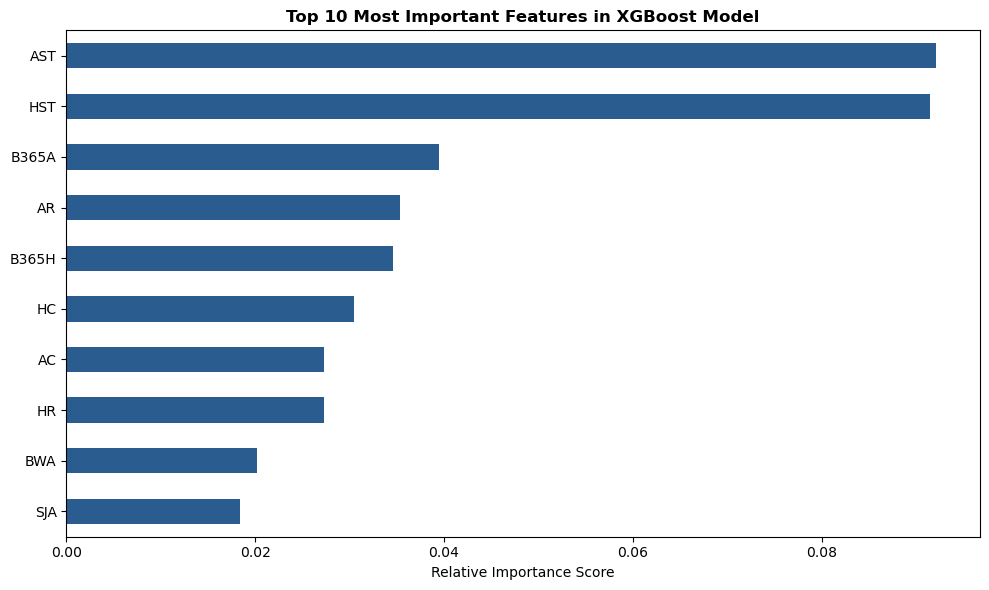

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# Get feature importances from your trained model
importances = pd.Series(model_b365.feature_importances_, index=X.columns)

# Plot top 10 features horizontally
plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='#2b5c8f')
plt.title('Top 10 Most Important Features in XGBoost Model', fontsize=12, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.gca().invert_yaxis()  # Put the highest at the top
plt.tight_layout()
plt.show()

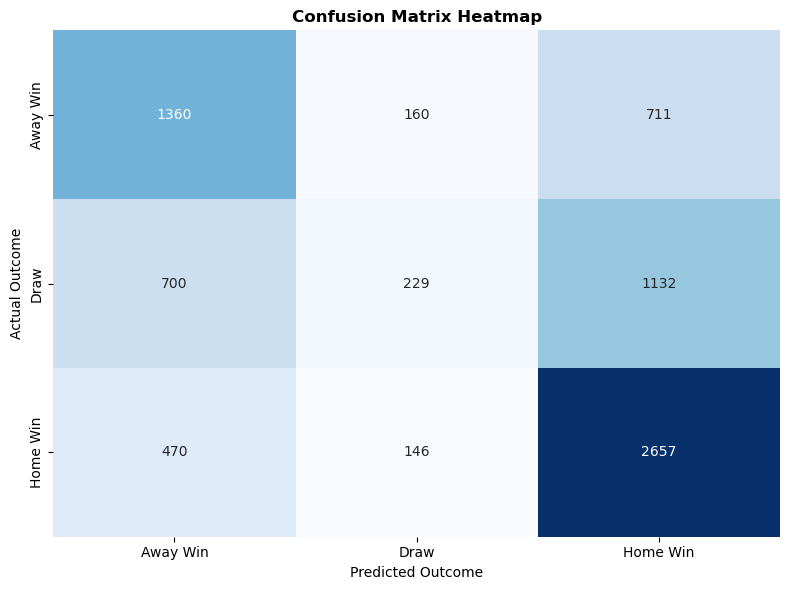

In [10]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Generate confusion matrix
cm = confusion_matrix(y_val, preds)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Away Win', 'Draw', 'Home Win'],
            yticklabels=['Away Win', 'Draw', 'Home Win'])
plt.title('Confusion Matrix Heatmap', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Outcome', fontsize=10)
plt.ylabel('Actual Outcome', fontsize=10)
plt.tight_layout()
plt.show()

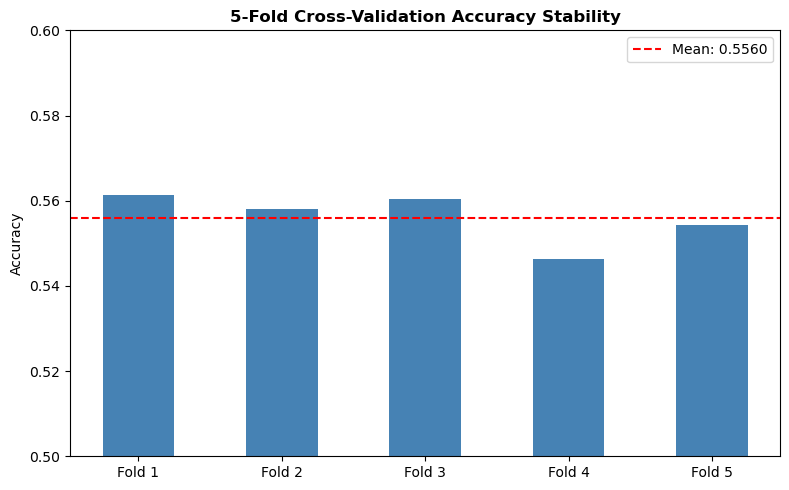

In [11]:
plt.figure(figsize=(8, 5))
folds = [f"Fold {i+1}" for i in range(len(cv_scores))]
plt.bar(folds, cv_scores, color='#4682B4', width=0.5)
plt.axhline(cv_scores.mean(), color='red', linestyle='--', label=f'Mean: {cv_scores.mean():.4f}')
plt.ylim(0.5, 0.6)  # Focus the axis around your accuracy range
plt.title('5-Fold Cross-Validation Accuracy Stability', fontsize=12, fontweight='bold')
plt.ylabel('Accuracy')
plt.legend()
plt.tight_layout()
plt.show()